# A / B Test
för andelar (binär data)

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [35]:
df = pd.read_csv('../files/simulated_data.csv', parse_dates=['date'])
display(df.head())
df.info()
df.select_dtypes(include='number').describe()

,group,outcome,date
0,A,0,2026-10-01
1,A,1,2026-10-01
2,A,0,2026-10-01
3,A,0,2026-10-01
4,A,0,2026-10-01


<class 'pandas.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   group    312 non-null    str           
 1   outcome  312 non-null    int64         
 2   date     312 non-null    datetime64[us]
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 7.4 KB


,outcome
count,312.000000
mean,0.288462
std,0.453775
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [36]:
summary = df.groupby('group')['outcome'].agg(
    observations='count',
    successes='sum',
    proportion='mean'
).reset_index()

# 95 % CI
z = stats.norm.ppf(0.975) # 0.975 är +- 1.96 * osäkerhet
ci_low, ci_high = [], []

for _, row in summary.iterrows():
    n = row['observations']
    p = row['proportion']
    se = np.sqrt(p*(1-p)/n)
    ci_low.append(p - z * se)
    ci_high.append(p + z * se)

# konfidensintervallet är för andel
summary['ci_low'] = ci_low
summary['ci_high'] = ci_high
summary


,group,observations,successes,proportion,ci_low,ci_high
0,A,175,42,0.240000,0.176724,0.303276
1,B,137,48,0.350365,0.270477,0.430253


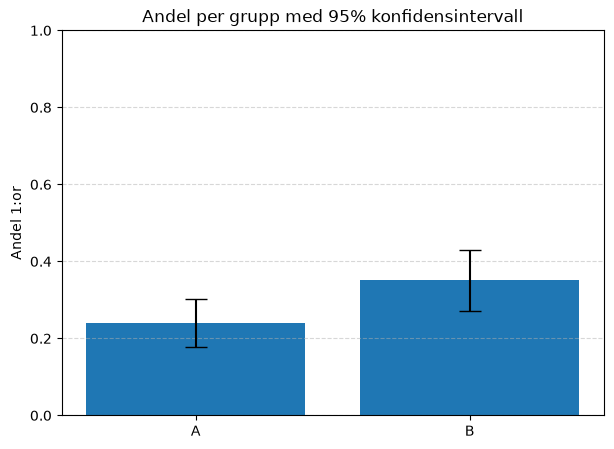

In [37]:
fig, ax =plt.subplots(figsize=(7,5))
x = np.arange(len(summary))
ax.bar(x, summary['proportion'], yerr=[summary['proportion']- summary['ci_low'], 
summary['ci_high'] - summary['proportion']], capsize = 8
)

ax.set_xticks(x)
ax.set_xticklabels(summary['group'])
ax.set_ylim(0,1)
ax.set_ylabel('Andel 1:or')
ax.set_title('Andel per grupp med 95% konfidensintervall')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


- H0 (nollhypotes): Det finns ingen verklig skillnad i andel mellan B och A i populationen
- H1 (tvåsidig mothypotes): Det finns en skillnad (okänt om B är större än A eller A är större än B)
- H1 (ensidig, bestäms i förväg): B har högre andel än A. (bör undvikas för det mesta)

In [38]:
n_A = int(summary.loc[summary['group'] == 'A', 'observations'].values[0]) # antal obesrvationer i grupp A
n_B = int(summary.loc[summary['group'] == 'B', 'observations'].values[0])
x_A = int(summary.loc[summary['group'] == 'A', 'successes'].values[0])  # antal 1 i grupp A
x_B = int(summary.loc[summary['group'] == 'B', 'successes'].values[0])

p_A = x_A / n_A # räknar andelar
p_B = x_B / n_B
diff = p_B - p_A # diff mellan andelarna

p_pooled = (x_A + x_B ) / (n_A + n_B) # andelar av helheten både grupp A och B
se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1 / n_A + 1 / n_B)) # standardfel

z_stat = diff / se_pooled

p_two_sided = 2 * (1 - stats.norm.cdf(abs(z_stat)))
p_one_sided_B_greater = 1 - stats.norm.cdf(z_stat)

print('Z-testets teststatistika, det standardiserade måttet på skillnaden mellan andelarna:', z_stat)
print('P-värdet för tvåsidigt z-test, probability:', p_two_sided)
print('P-värdet för ensidigt z-test:', p_one_sided_B_greater)
print('diff:', diff)

Z-testets teststatistika, det standardiserade måttet på skillnaden mellan andelarna: 2.135453342617615
P-värdet för tvåsidigt z-test, probability: 0.03272399744817189
P-värdet för ensidigt z-test: 0.016361998724085947
diff: 0.11036496350364966


1. Skillnaden mellan grupperna (diff) +0,1104 Det motsvarar 11,04 procentenheter.
2. Z-testets teststatistika 2,1355 Det betyder att den observerade skillnaden ligger cirka 2,14 standardfel från den skillnad på noll som förväntas enligt nollhypotesen.
3. P-värdet för tvåsidigt test 0,03272 Det innebär att om nollhypotesen är sann, är sannolikheten cirka 3,27 % att få en skillnad som är minst lika extrem som den observerade, i någon riktning. Det betyder att vi **förkastar** nollhypotesen på 5 % signifikansnivå.

Det fanns en statistiskt signifikant skillnad i andelen positiva utfall mellan grupperna. Grupp B hade en högre andel positiva utfall (35,04 %) jämfört med grupp A (24,00 %), vilket motsvarar en skillnad på 11,04 procentenheter. Ett tvåsidigt z-test för skillnad mellan två andelar visade att skillnaden var statistiskt signifikant (z = 2,14, p = 0,0327).

En statistisk reservation: Detta bygger på normalapproximationen och ett poolat standardfel under nollhypotesen. Testet förutsätter oberoende observationer och tillräckligt stora förväntade antal i respektive utfallskategori. Dina gruppstorlekar och andelar uppfyller dessa villkor.
Statistisk signifikans innebär inte automatiskt att skillnaden är praktiskt betydelsefull eller att gruppindelningen orsakar skillnaden.

In [39]:
se = np.sqrt(p_A * (1 - p_A) / n_A + p_B * (1-p_B) / n_B)
z_crit = stats.norm.ppf(0.975)
ci_low = diff - z_crit * se
ci_high = diff + z_crit * se
print([ci_low, ci_high], diff)

[np.float64(0.008453095686323714), np.float64(0.2122768313209756)] 0.11036496350364966


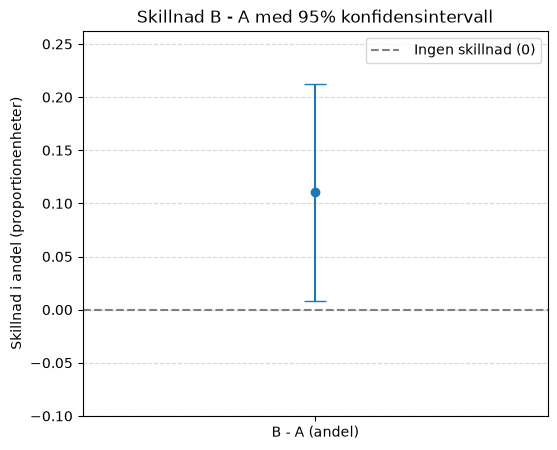

In [40]:
fig, ax = plt.subplots(figsize=(6,5))
ax.errorbar([0], [diff], yerr = [[diff - ci_low], [ci_high - diff]], fmt='o', capsize=8)
ax.axhline(0, linestyle='--', color='grey', label=' Ingen skillnad (0)')
ax.set_xticks([0])
ax.set_xticklabels(['B - A (andel)'])
ax.set_ylim(min(-0.1, ci_low - 0.05), max(0.1, ci_high + 0.05))
ax.set_ylabel('Skillnad i andel (proportionenheter)')
ax.set_title('Skillnad B - A med 95% konfidensintervall')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [41]:
absolute_pp = diff * 100
relative_lift = (p_B / p_A - 1) * 100 if p_A > 0 else np.inf
absolute_pp, relative_lift

(11.036496350364967, 45.98540145985404)

absolut diff i procentenheter 11 %
relativ effektstorlek = 46 %

# A/B-test för andelar
Ett A/B-test jämför två varianter för att undersöka om de ger olika resultat. När utfallet endast har två möjliga värden, exempelvis köp eller inget köp, arbetar vi med andelar.  
I den här lektionen följer vi ett fullständigt analysflöde: data kontrolleras och sammanfattas, gruppernas andelar jämförs och skillnaden analyseras med konfidensintervall och ett z-test.

#### Binära utfall och andelar
Ett binärt utfall har två möjliga värden. Det kan kodas som:
- 1 för ett positivt utfall
- 0 för ett negativt utfall

Exempel på binära utfall är:
- klickade eller klickade inte
- genomförde ett köp eller genomförde inget köp
- svarade ja eller svarade nej
- tillfrisknade eller tillfrisknade inte  

När observationerna är kodade med noll och ett är medelvärdet samma sak som andelen ettor.
Om en grupp innehåller 100 personer och 28 av dem genomför ett köp blir medelvärdet:
28 / 100 = 0,28
Andelen genomförda köp är alltså 0,28 eller 28%

#### Kontrollera data före analysen
Innan grupperna jämförs behöver vi kontrollera att datan motsvarar experimentets upplägg.
För ett binärt utfall bör vi bland annat undersöka:
- att varje observation tillhör rätt grupp
- att utfallen endast innehåller de tillåtna värdena noll och ett
- om det finns saknade värden
- om det finns dubbletter
- om samma person förekommer flera gånger när observationerna ska vara oberoende
-om grupperna skapades genom den avsedda slumpmässiga fördelningen

Det räcker inte att koden kan genomföra testet. Resultatet blir endast meningsfullt om datan och experimentets design är rimliga.

## Absolut och relativ skillnad
Låt andelen i grupp A betecknas med pA och andelen i grupp B med pB.  
Den absoluta skillnaden beräknas som:  
**skillnad = pB − pA**  
Om andelarna skrivs i procent uttrycks den absoluta skillnaden i procentenheter.  
Den relativa förändringen beräknas i förhållande till grupp A:  
**relativ förändring = (pB / pA − 1) × 100**  
Den absoluta och relativa förändringen svarar på olika frågor:  
- Procentenheter: Hur mycket större eller mindre är andelen?
- Relativ förändring: Hur stor är förändringen i förhållande till utgångsläget?  

Båda måtten kan vara användbara, men det måste framgå vilket som redovisas. Den relativa förändringen kan dessutom bli missvisande när andelen i grupp A är mycket liten.

## Hypoteser för två andelar
Vid ett tvåsidigt test kan hypoteserna skrivas:  
**Nollhypotes, H₀: pB − pA = 0**  
**Alternativhypotes, H₁: pB − pA ≠ 0**  
Nollhypotesen säger att grupperna har samma andel i populationen. Den observerade skillnaden i stickprovet förklaras då av slumpmässig variation.  
Det tvåsidiga alternativet säger att andelarna skiljer sig, utan att i förväg bestämma vilken grupp som har den högre andelen.  
Om frågeställningen och riktningen har bestämts innan data analyseras kan ett ensidigt alternativ ibland användas, exempelvis:  
**H₁: pB > pA**
Riktningen får inte väljas i efterhand efter att vi har sett vilken grupp som fick bäst resultat.

## Z-test för två andelar
Ett z-test jämför den observerade skillnaden med hur mycket skillnaden förväntas variera om nollhypotesen gäller.  
Grundidén är:  
**z = observerad skillnad / skillnadens standardfel**  
Ett z-värde nära noll innebär att skillnaden är liten i förhållande till osäkerheten. Ett z-värde långt från noll innebär att den observerade skillnaden är stor i förhållande till den variation som förväntas av slumpen.  
När standardfelet för hypotesprovet beräknas används en **poolad andel**. Observationerna från båda grupperna används då för att uppskatta en gemensam andel.  
Det görs eftersom nollhypotesen utgår från att grupperna har samma andel i populationen. Om nollhypotesen gäller är den gemensamma andelen den relevanta utgångspunkten för att beräkna den förväntade slumpvariationen.  
Z-värdet används sedan för att beräkna ett p-värde.

## Konfidensintervall för skillnaden
P-värdet undersöker hur förenligt resultatet är med nollhypotesen. Konfidensintervallet beskriver i stället vilka storlekar på skillnaden som är rimliga utifrån data.  
För konfidensintervallet används gruppernas observerade andelar var för sig när standardfelet beräknas. Detta kallas ibland ett **opoolat standardfel**.  
Intervallet byggs runt den observerade skillnaden:  
**observerad skillnad ± kritiskt värde × standardfel**  
För ett ungefärligt 95-procentigt intervall används det kritiska värdet 1,96.  
- Om intervallet innehåller noll är en population utan skillnad förenlig med data.
- Om hela intervallet ligger över noll talar resultatet för att andelen i B är högre.
- Om hela intervallet ligger under noll talar resultatet för att andelen i B är lägre.
- Intervallets bredd visar hur osäker skattningen är.  

Vi bör analysera konfidensintervallet för **själva skillnaden**. Att endast titta på om gruppernas separata konfidensintervall överlappar är inte ett tillförlitligt hypotesprov.

## När fungerar normalapproximationen?
Z-testet och intervallet som användes i lektionsvideon bygger på en normalapproximation. Den fungerar bäst när båda grupperna innehåller tillräckligt många positiva och negativa utfall.  
En vanlig tumregel är att varje grupp bör ha åtminstone ungefär 5–10 förväntade observationer av varje utfall. Det räcker alltså inte alltid att en grupp totalt innehåller många observationer.  
Om utfallet är mycket ovanligt eller grupperna är små kan normalapproximationen bli osäker. Då kan andra metoder, exempelvis ett exakt test eller andra typer av konfidensintervall, vara mer lämpliga.

### Från statistiskt resultat till beslut
Ett A/B-test bör inte bedömas enbart utifrån om p-värdet ligger över eller under 0,05.
En tydlig redovisning bör innehålla:  
- andelen i grupp A
- andelen i grupp B
- skillnaden i procentenheter
- den relativa förändringen, om den är relevant
- konfidensintervallet för skillnaden
- p-värdet och vilket test som användes
- en bedömning av skillnadens praktiska betydelse

Ett lovande resultat kan fortfarande vara för osäkert för att motivera ett beslut. Ett statistiskt signifikant resultat kan på motsvarande sätt vara för litet för att ha praktisk betydelse.

### Bestäm när experimentet ska avslutas
Stickprovsstorleken och stopptiden bör så långt som möjligt bestämmas innan experimentet startar.  
Om vi kontrollerar p-värdet upprepade gånger och avslutar experimentet så fort resultatet blir signifikant ökar risken för ett falskt positivt resultat. Varje ny kontroll blir ytterligare en möjlighet för slumpvariation att passera beslutsgränsen.  
Om resultat behöver övervakas löpande bör en metod som är anpassad för sekventiell analys användas. I ett vanligt A/B-test är det enklare att i förväg bestämma:  
- önskad stickprovsstorlek
- experimentets längd
- primärt utfall
- signifikansnivå
- minsta praktiskt betydelsefulla effekt  

## A/B-test från princip till praktik
#### Börja med en analysplan
Innan experimentet startar bör vi bestämma:  
- vilken population vi vill uttala oss om
- vilken förändring som jämförs med kontrollgruppen
- vilken primär mätvariabel som ska analyseras
- om utfallet är binärt eller kontinuerligt
- vilken skillnad som är praktiskt betydelsefull
- vilken signifikansnivå som ska användas
- om testet ska vara ensidigt eller tvåsidigt
- hur stort stickprovet behöver vara
- när experimentet ska avslutas
- vilka eventuella sekundära analyser som ska genomföras  

En analysplan minskar risken att vi ändrar frågeställningen eller väljer metod efter att vi har sett resultatet.  
Den praktiskt betydelsefulla skillnad som testet planeras för kallas ibland **minsta detekterbara effekt**, eller MDE efter engelskans minimum detectable effect. Den behöver bestämmas utifrån verksamhetens behov, inte enbart utifrån vad som är lättast att upptäcka statistiskt.


### Sanna och observerade värden
I en simulering bestämmer vi hur den fiktiva populationen fungerar. Vi kan exempelvis bestämma att:
- grupp A har en sann konverteringsgrad på 26 %
- grupp B har en sann konverteringsgrad på 31 %
Den sanna skillnaden är då 5 procentenheter.
När vi skapar ett stickprov från dessa populationer får vi observerade andelar. På grund av slumpvariation kommer de sällan att bli exakt 26 % och 31 %.
Det är viktigt att skilja mellan:
- sann effekt: den skillnad som finns i den simulerade populationen
- observerad effekt: den skillnad som råkar uppstå i ett visst stickprov
- skattad osäkerhet: hur mycket den observerade effekten kan förväntas variera

I verkliga undersökningar känner vi inte den sanna effekten. Det är den vi försöker uppskatta med hjälp av stickprovet.

### Från ett experiment till många
Ett enda simulerat experiment visar ett möjligt resultat. För att uppskatta testets power behöver vi upprepa experimentet många gånger.  
Ett förenklat simuleringsflöde är:  
- 1. Skapa ett nytt stickprov för grupp A och grupp B.
- 2. Beräkna gruppernas observerade resultat.
- 3. Genomför det planerade statistiska testet.
- 4. Kontrollera om p-värdet är mindre än signifikansnivån.
- 5. Upprepa processen många gånger.
- 6. Beräkna andelen experiment där nollhypotesen förkastades.

Om den sanna effekten finns i varje simulering motsvarar denna andel en uppskattning av testets power.  
Om 800 av 1 000 simulerade experiment upptäcker effekten blir den uppskattade powern:
**800 / 1 000 = 0,80 = 80 %**
Det betyder inte att ett visst experiment har 80 % sannolikhet att ge rätt svar. Det betyder att samma experimentupplägg, upprepat många gånger i en värld där den angivna effekten finns, skulle upptäcka effekten i ungefär 80% av experimenten.

### Vad påverkar power?
Power ökar vanligtvis när:  
- stickprovet blir större
- den verkliga effekten blir större
- variationen i data blir mindre
- mätningen blir mer tillförlitlig
En liten effekt är svårare att skilja från slumpvariation och kräver därför ofta ett större stickprov.  
Sambandet innebär också att frågan ”Hur många observationer behöver vi?” inte har ett enda generellt svar. Stickprovsstorleken beror bland annat på:  
- utgångsnivån i kontrollgruppen
- den minsta effekt vi vill kunna upptäcka
- önskad power
- signifikansnivån
- om testet är ensidigt eller tvåsidigt

Ett vanligt mål är minst 80 % power, men den lämpliga nivån beror på konsekvenserna av att missa en verklig effekt.

### Simulerad power är en uppskattning
En simulering bygger själv på slumpmässiga stickprov. Om simuleringen körs igen kan resultatet därför förändras något.
För att göra analysen mer stabil och reproducerbar bör vi:
- använda många simuleringar
- sätta ett slumpfrö när analysen ska kunna återskapas
- dokumentera alla parametrar
- undvika att tolka en enskild decimalskillnad som exakt

Simulering är särskilt användbar när vi vill förstå hur en metod fungerar eller när en analytisk beräkning är svår. För vanliga tester finns det också etablerade funktioner för att beräkna power och stickprovsstorlek.

## Välj test efter mätvariabeln
Det statistiska testet ska väljas utifrån frågeställningen, datans struktur och typen av utfall.  

#### Binärt utfall
Exempel:
- köp eller inget köp
- klick eller inget klick
- ja eller nej
Här jämför vi vanligtvis andelar. För tillräckligt stora oberoende grupper kan vi använda ett **z-test för två andelar.**  
Färdiga funktioner kan även beräkna:  
- gruppernas observerade andelar
- z-värde och p-värde
- konfidensintervall för respektive andel
- konfidensintervall för skillnaden

Ett Wilson-intervall är ofta ett bättre val för en enskild andel än det enklaste intervallet baserat direkt på normalapproximationen, särskilt när stickprovet är mindre eller andelen ligger nära noll eller ett.

#### Kontinuerligt utfall
Exempel:  
- köpesumma
- leveranstid
- antal minuter
- blodtryck

Här jämför vi ofta gruppernas medelvärden. För två oberoende grupper är **Welch-testet** vanligtvis ett bra standardval eftersom det inte kräver att populationerna har samma varians.
Om observationerna är parade, exempelvis mätningar på samma personer före och efter en förändring, behövs i stället en metod som tar hänsyn till parningen.

#### Färdiga funktioner ersätter inte förståelse
Statistikbibliotek som SciPy och statsmodels innehåller färdiga funktioner för vanliga test och konfidensintervall. De minskar mängden kod och risken för fel i den manuella beräkningen.  
Vi behöver ändå kontrollera:  
- att rätt test har valts
- i vilken ordning grupperna skickas till funktionen
- vilket alternativ som används
- att observationerna uppfyller metodens antaganden
- vilken metod som används för konfidensintervallet
- i vilken enhet effekten redovisas
- hur funktionens resultat ska tolkas

Ett korrekt beräknat p-värde kan fortfarande besvara fel fråga om analysen har planerats på ett olämpligt sätt.

#### Många tester ger fler falsklarm
Om vi genomför många oberoende test med signifikansnivån 0,05 ökar sannolikheten att minst ett test blir signifikant av en slump.  
En enkel korrigering är Bonferronimetoden:  
**justerad signifikansnivå = önskad total signifikansnivå / antal tester**  
Om fem test genomförs och den totala nivån ska vara 0,05 används gränsen:  
**0,05 / 5 = 0,01**  
Bonferronimetoden är enkel men kan vara konservativ, vilket innebär att verkliga effekter blir svårare att upptäcka.

#### Redovisa hela analysen
En reproducerbar redovisning av ett A/B-test bör innehålla:
- syftet med experimentet
- primärt och eventuella sekundära utfall
- gruppernas storlek
- gruppernas observerade resultat
- effektskattning i en begriplig enhet
- konfidensintervall
- använt test och p-värde
- planerad signifikansnivå
- hur stickprovsstorlek och stopptid bestämdes
- eventuella korrigeringar för flera tester
- en praktisk tolkning och rekommendation

Det gör det möjligt för andra att förstå både vad analysen visar och vilka begränsningar den har.

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
np.random.seed(0)

In [43]:
baseline_rate_A = 0.26
true_lift_pp = 0.05
alpha_level = 0.05

sample_sizes_to_try = [50, 100, 150, 200, 300, 500, 800]

In [44]:
def run_one_ab_proportion_test(n_per_group, true_p_A, true_p_B, alternative='two-sided'):
    x_success_A = np.random.binomial(n_per_group, true_p_A)
    x_success_B = np.random.binomial(n_per_group, true_p_B)

    obs_p_A = x_success_A / n_per_group
    obs_p_B = x_success_B / n_per_group
    obs_diff = obs_p_B - obs_p_A

    pooled = (x_success_A + x_success_B) / (2 * n_per_group)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n_per_group + 1 / n_per_group))

    z_value = obs_diff / se

    if alternative == 'two-sided':
        p_value = 2 * (1-stats.norm.cdf(abs(z_value)))
    elif alternative == 'greater':
        p_value = 1 - stats.norm.cdf(z_value)
    else:
        p_value = stats.norm.cdf(z_value)

    return dict(
        x_success_A = x_success_A,
        x_success_B = x_success_B,
        obs_p_A = obs_p_A,
        obs_p_B = obs_p_B,
        obs_diff = obs_diff,
        z_value = z_value,
        p_value = p_value
    )

run_one_ab_proportion_test(100, baseline_rate_A, baseline_rate_A+true_lift_pp)

{'x_success_A': 26,
 'x_success_B': 35,
 'obs_p_A': 0.26,
 'obs_p_B': 0.35,
 'obs_diff': 0.08999999999999997,
 'z_value': np.float64(1.3822455156044657),
 'p_value': np.float64(0.16689632898196027)}

In [45]:
n_demo = 300
res = run_one_ab_proportion_test(n_demo, baseline_rate_A, baseline_rate_A + true_lift_pp)
p_A_hat, p_B_hat = res['obs_p_A'], res['obs_p_B'] # packar upp resultaten från dictionaryn vi får av funktionen
diff_hat = p_B_hat - p_A_hat

se_unpooled = np.sqrt(p_A_hat * (1 - p_A_hat) / n_demo + p_B_hat * (1 - p_B_hat) / n_demo)
z_crit = stats.norm.ppf(0.975)
ci_low_prop = diff_hat - z_crit * se_unpooled
ci_high_prop = diff_hat + z_crit * se_unpooled

print(diff_hat, ci_low_prop, ci_high_prop, p_A_hat, p_B_hat)

0.06666666666666665 -0.0030297881706780605 0.13636312150401136 0.22333333333333333 0.29


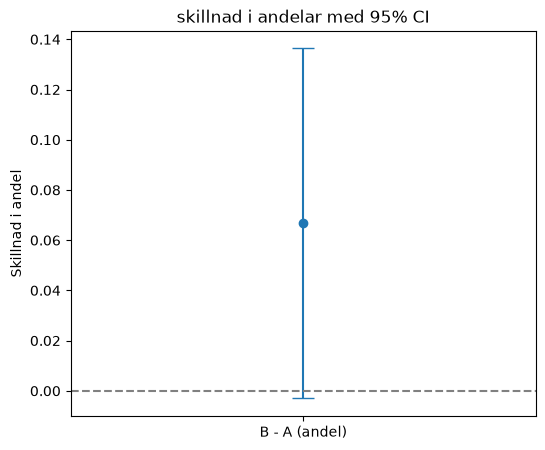

In [46]:
fig, ax = plt.subplots(figsize=(6,5))
ax.errorbar([0], [diff_hat], yerr=[[diff_hat - ci_low_prop], [ci_high_prop - diff_hat]], fmt='o', capsize=8)
ax.axhline(0, linestyle='--', color='grey', label='ingen skillnad (0)')
ax.set_xticks([0])
ax.set_xticklabels(['B - A (andel)'])
ax.set_ylabel('Skillnad i andel')
ax.set_title('skillnad i andelar med 95% CI')
plt.show()

In [47]:
# power är andel simuleringar där p är mindre än alpha
def estimate_power_by_simulation(n_per_group, true_p_A, true_p_B, alpha=0.05, alternative='two-sided', num_simulations=5000):
    detections = 0
    for _ in range(num_simulations):
        res = run_one_ab_proportion_test(n_per_group, true_p_A, true_p_B, alternative)
        if res['p_value'] < alpha:
            detections += 1 

    return detections / num_simulations

sim_power = []
for n in sample_sizes_to_try:
    pwr = estimate_power_by_simulation(n, baseline_rate_A, baseline_rate_A + true_lift_pp, alpha_level, 'two-sided', 3000)
    sim_power.append(pwr)

pd.DataFrame({'n_per_group': sample_sizes_to_try, 'simulated_power': sim_power})

,n_per_group,simulated_power
0,50,0.082333
1,100,0.116667
2,150,0.174667
3,200,0.195000
4,300,0.270667
5,500,0.426333
6,800,0.613667


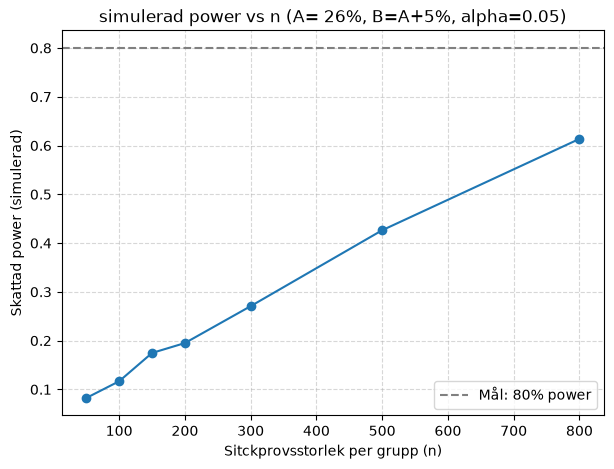

In [52]:
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(sample_sizes_to_try, sim_power, marker='o')
ax.axhline(0.8, color='grey', linestyle='--', label='Mål: 80% power')
ax.set_xlabel('Sitckprovsstorlek per grupp (n)')
ax.set_ylabel('Skattad power (simulerad)')
ax.set_title(f'simulerad power vs n (A= {baseline_rate_A:.0%}, B=A+{true_lift_pp:.0%}, alpha={alpha_level})')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.show()

In [56]:
def min_n_for_target_power_sim(true_p_A, true_p_B, alpha=0.05, target_power=0.8, n_low=20, n_high=5000, alternative='two-sided', num_sim=2000):
    low, high = n_low, n_high
    best = None
    while low <= high:
        mid = (low + high) // 2
        pwr = estimate_power_by_simulation(mid, true_p_A, true_p_B, alpha, alternative, num_sim)
        if pwr >= target_power:
            best = (mid, pwr)
            high = mid - 1
        else:
            low = mid + 1

    return best

min_n_estimate = min_n_for_target_power_sim(
    baseline_rate_A,
    baseline_rate_A + true_lift_pp, 
    alpha_level,
    0.8,
    20,
    2000, 
    'two-sided',
    1500
)
min_n_estimate

(1312, 0.8193333333333334)

In [69]:
from statsmodels.stats.proportion import proportions_ztest

n_A_prop, n_B_prop = 220, 240
true_p_A_demo, true_p_B_demo = 0.26, 0.31
A_outcomes = np.random.binomial(1, true_p_A_demo, size = n_A_prop)
B_outcomes = np.random.binomial(1, true_p_B_demo, size = n_B_prop)

df_prop = pd.DataFrame({
    'group': ['A'] * n_A_prop + ['B'] * n_B_prop,
    'outcome': np.concatenate([A_outcomes, B_outcomes])
})

counts = df_prop.groupby('group')['outcome'].agg(successes='sum', observations='count').reset_index()
x_A = counts.loc[counts.group == 'A', 'successes'].iloc[0].item()
n_A = counts.loc[counts.group == 'A', 'observations'].iloc[0].item()
x_B = counts.loc[counts.group == 'B', 'successes'].iloc[0].item()
n_B = counts.loc[counts.group == 'B', 'observations'].iloc[0].item()

z_stat, p_val = proportions_ztest(count=[x_A, x_B], nobs=[n_A, n_B], alternative='two-sided')
p_A = x_A / n_A
p_B = x_B / n_B
diff_pp = (p_B - p_A) * 100
z_stat, p_val, p_A, p_B, diff_pp

(np.float64(-1.326109759314268),
 np.float64(0.1848033439790897),
 0.2409090909090909,
 0.29583333333333334,
 5.492424242424243)